# VAE Assignment 1: VAE Mathematical Implementation

| Part | Task |
|---|---|
| 1 | Architecture of a Variational Autoencoder (with diagram) |
| 2 | Derivation of the Evidence Lower Bound (ELBO) |
| 3 | The reparameterisation trick |
| 4 | Numerical example: computing a latent sample $z$ |
| 5 | Numerical example: reconstruction loss and KL-divergence |
| 6 | Full PyTorch implementation, plus the effect of latent dimension on reconstruction quality |

> ⚡ Training uses **MNIST** with a small fully-connected VAE and only **3 epochs per model**. That is enough to show the full process and the trend across latent sizes.

## Setup

In [1]:
import os, time, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision

warnings.filterwarnings("ignore")
sns.set_style("white")

def set_seed(s=42):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
set_seed(42)

device = torch.device("cuda" if torch.cuda.is_available()
                      else "mps" if torch.backends.mps.is_available() else "cpu")
print("Device:", device)
os.makedirs("data", exist_ok=True)

Device: mps


---
## Part 1: Architecture of a Variational Autoencoder

A VAE is a **generative latent-variable model**. It assumes each observation $x$ (e.g. an image) was generated from an unobserved, **continuous** latent vector $z$:

$$z \sim p(z)=\mathcal{N}(0, I), \qquad x \sim p_\theta(x\mid z)$$

It has three parts:

| Component | Network | Output |
|---|---|---|
| **Encoder** (inference / recognition network) $q_\phi(z\mid x)$ | NN with parameters $\phi$ | mean $\mu(x)$ and log-variance $\log\sigma^2(x)$ of a Gaussian over $z$ |
| **Latent space** | sampling with the reparameterisation trick | $z = \mu + \sigma \odot \epsilon$, $\epsilon\sim\mathcal{N}(0,I)$ |
| **Decoder** (generative network) $p_\theta(x\mid z)$ | NN with parameters $\theta$ | reconstruction $\hat{x}$ (Bernoulli means for each pixel) |

Unlike a plain autoencoder, the encoder outputs a **distribution**, not a single point. The KL term forces these distributions to stay close to $\mathcal{N}(0,I)$, which makes the latent space **smooth and continuous**, so we can sample new data from it.

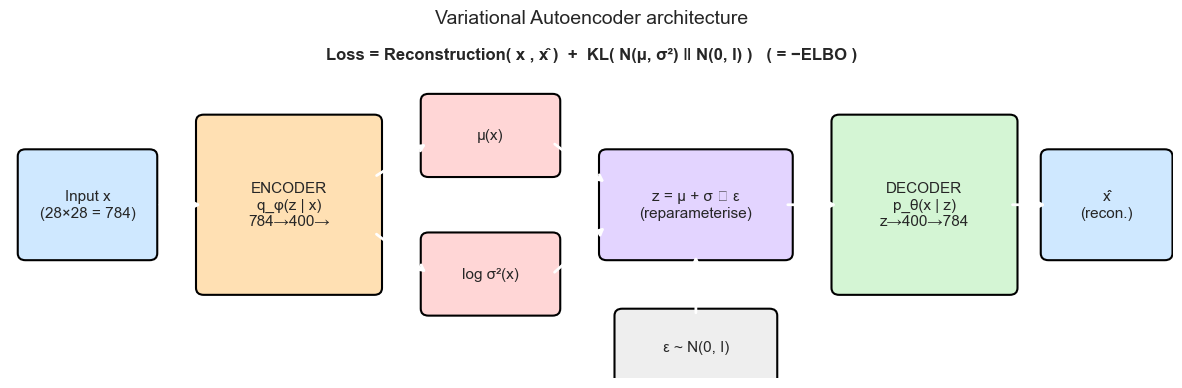

In [2]:
# ---- Neat architecture diagram drawn with matplotlib ----
from matplotlib.patches import FancyBboxPatch
fig, ax = plt.subplots(figsize=(15, 4.5)); ax.axis("off"); ax.set_xlim(0, 15); ax.set_ylim(0, 5)
def box(x, y, w, h, text, color):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.1", fc=color, ec="black", lw=1.5))
    ax.text(x + w / 2, y + h / 2, text, ha="center", va="center", fontsize=11)
def arrow(x1, y1, x2, y2):
    ax.annotate("", xy=(x2, y2), xytext=(x1, y1), arrowprops=dict(arrowstyle="->", lw=2))

box(0.2, 1.8, 1.6, 1.4, "Input x\n(28×28 = 784)", "#cfe8ff")
box(2.5, 1.3, 2.2, 2.4, "ENCODER\nq_φ(z | x)\n784→400→", "#ffe0b3")
box(5.4, 3.0, 1.6, 1.0, "μ(x)", "#ffd6d6"); box(5.4, 1.0, 1.6, 1.0, "log σ²(x)", "#ffd6d6")
box(7.7, 1.8, 2.3, 1.4, "z = μ + σ ⊙ ε\n(reparameterise)", "#e3d4ff")
box(7.9, 0.0, 1.9, 0.9, "ε ~ N(0, I)", "#eeeeee")
box(10.7, 1.3, 2.2, 2.4, "DECODER\np_θ(x | z)\nz→400→784", "#d4f5d4")
box(13.4, 1.8, 1.5, 1.4, "x̂\n(recon.)", "#cfe8ff")
arrow(1.9, 2.5, 2.5, 2.5); arrow(4.7, 2.9, 5.4, 3.4); arrow(4.7, 2.1, 5.4, 1.5)
arrow(7.0, 3.4, 7.7, 2.8); arrow(7.0, 1.5, 7.7, 2.2); arrow(8.85, 0.9, 8.85, 1.8)
arrow(10.0, 2.5, 10.7, 2.5); arrow(12.9, 2.5, 13.4, 2.5)
ax.text(7.5, 4.6, "Loss = Reconstruction( x , x̂ )  +  KL( N(μ, σ²) ‖ N(0, I) )   ( = −ELBO )",
        ha="center", fontsize=12, fontweight="bold")
plt.title("Variational Autoencoder architecture", fontsize=14); plt.show()

---
## Part 2: Derivation of the ELBO

We want to maximise the **marginal likelihood** of the data:

$$\log p_\theta(x) = \log \int p_\theta(x\mid z)\,p(z)\,dz$$

This integral is **intractable**, because it requires integrating over all $z$ through a neural network. We introduce the encoder distribution $q_\phi(z\mid x)$ as an approximation of the true posterior $p_\theta(z\mid x)$.

**Step 1: multiply and divide by $q_\phi(z\mid x)$**
$$\log p_\theta(x) = \log \int q_\phi(z\mid x)\,\frac{p_\theta(x\mid z)p(z)}{q_\phi(z\mid x)}\,dz = \log \mathbb{E}_{q_\phi(z\mid x)}\!\left[\frac{p_\theta(x\mid z)p(z)}{q_\phi(z\mid x)}\right]$$

**Step 2: Jensen's inequality** ($\log$ is concave, so $\log\mathbb{E}[\cdot] \ge \mathbb{E}[\log \cdot]$)
$$\log p_\theta(x) \;\ge\; \mathbb{E}_{q_\phi(z\mid x)}\!\left[\log \frac{p_\theta(x\mid z)p(z)}{q_\phi(z\mid x)}\right] \;=:\; \mathcal{L}(\theta,\phi;x) \quad\text{(ELBO)}$$

**Step 3: split the log**
$$\mathcal{L} = \mathbb{E}_{q_\phi(z\mid x)}[\log p_\theta(x\mid z)] \;+\; \mathbb{E}_{q_\phi(z\mid x)}\!\left[\log \frac{p(z)}{q_\phi(z\mid x)}\right]$$

$$\boxed{\;\mathcal{L}(\theta,\phi;x) = \underbrace{\mathbb{E}_{q_\phi(z\mid x)}[\log p_\theta(x\mid z)]}_{\text{reconstruction term}} \;-\; \underbrace{D_{KL}\big(q_\phi(z\mid x)\,\|\,p(z)\big)}_{\text{regularisation term}}\;}$$

**Exact gap (alternative derivation).** One can also show
$$\log p_\theta(x) = \mathcal{L}(\theta,\phi;x) + D_{KL}\big(q_\phi(z\mid x)\,\|\,p_\theta(z\mid x)\big)$$
The KL divergence is $\ge 0$, so the ELBO is a lower bound. It becomes tight when the encoder matches the true posterior. Maximising the ELBO therefore **(a)** increases the data likelihood and **(b)** improves the posterior approximation.

**Closed-form KL for Gaussians.** With $q_\phi(z\mid x)=\mathcal{N}(\mu,\mathrm{diag}(\sigma^2))$ and $p(z)=\mathcal{N}(0,I)$ over $J$ latent dimensions:
$$D_{KL} = -\frac{1}{2}\sum_{j=1}^{J}\left(1 + \log\sigma_j^2 - \mu_j^2 - \sigma_j^2\right)$$

**Reconstruction term.** For binary or [0,1] pixels, $p_\theta(x\mid z)$ is a Bernoulli distribution, so $-\log p_\theta(x\mid z)$ is the **binary cross-entropy** $-\sum_i [x_i\log\hat{x}_i + (1-x_i)\log(1-\hat{x}_i)]$. For real-valued data and a Gaussian decoder it becomes the **squared error** (up to constants).

**Training objective** (what we minimise):
$$\text{Loss} = -\mathcal{L} = \text{Reconstruction loss} + D_{KL}$$

---
## Part 3: The reparameterisation trick

To train with gradient descent we need $\nabla_\phi\, \mathbb{E}_{q_\phi(z\mid x)}[\log p_\theta(x\mid z)]$. Sampling $z \sim \mathcal{N}(\mu_\phi, \sigma_\phi^2)$ is a **random, non-differentiable** operation, so gradients cannot flow from the decoder back into the encoder.

**Trick:** move the randomness into an auxiliary variable that does **not** depend on $\phi$:
$$\epsilon \sim \mathcal{N}(0, I), \qquad z = \mu_\phi(x) + \sigma_\phi(x)\odot\epsilon$$

Now $z$ is a **deterministic, differentiable** function of $\mu$, $\sigma$ and the external noise $\epsilon$:
$$\frac{\partial z}{\partial \mu} = 1, \qquad \frac{\partial z}{\partial \sigma} = \epsilon$$

so back-propagation works end-to-end, and the expectation can be estimated with a single Monte-Carlo sample per data point. In practice the network outputs $\log\sigma^2$ (any real number) and we compute $\sigma = \exp(\tfrac12\log\sigma^2)$, which is always positive and numerically stable.

```
 Without trick:   x → encoder → (μ,σ) → [ sample z ]  ✘ gradient blocked → decoder
 With trick:      x → encoder → (μ,σ) ─┐
                                ε ~ N(0,I) ─┴→ z = μ + σ·ε  ✔ differentiable → decoder
```

In [3]:
# Demonstration: gradients flow through the reparameterised sample
mu = torch.tensor([0.5, -1.0], requires_grad=True)
sigma = torch.tensor([0.8, 0.3], requires_grad=True)
eps = torch.tensor([1.2, -0.5])
z = mu + sigma * eps
z.sum().backward()
print("dz/dmu    =", mu.grad.tolist(), " (always 1)")
print("dz/dsigma =", sigma.grad.tolist(), " (equals epsilon)")

dz/dmu    = [1.0, 1.0]  (always 1)
dz/dsigma = [1.2000000476837158, -0.5]  (equals epsilon)


---
## Part 4: Numerical example: latent sample with the reparameterisation trick

Given a 2-D latent distribution $q(z\mid x)=\mathcal{N}(\mu,\sigma^2)$ with

$$\mu = [0.5,\; -1.0], \qquad \sigma = [0.8,\; 0.3], \qquad \epsilon = [1.2,\; -0.5]$$

**Hand calculation**

$$z_1 = \mu_1 + \sigma_1\epsilon_1 = 0.5 + 0.8 \times 1.2 = 0.5 + 0.96 = \mathbf{1.46}$$
$$z_2 = \mu_2 + \sigma_2\epsilon_2 = -1.0 + 0.3 \times (-0.5) = -1.0 - 0.15 = \mathbf{-1.15}$$

$$\Rightarrow z = [1.46,\; -1.15]$$

In [4]:
mu    = np.array([0.5, -1.0])
sigma = np.array([0.8, 0.3])
eps   = np.array([1.2, -0.5])
z = mu + sigma * eps
print("z =", z)

# Same thing with the log-variance parameterisation used by the network
logvar = np.log(sigma ** 2)
print("logvar =", logvar.round(4), "-> sigma =", np.exp(0.5 * logvar), "-> z =", mu + np.exp(0.5 * logvar) * eps)

z = [ 1.46 -1.15]
logvar = [-0.4463 -2.4079] -> sigma = [0.8 0.3] -> z = [ 1.46 -1.15]


---
## Part 5: Numerical example: reconstruction loss and KL divergence

Input $x$ and reconstruction $\hat{x}$ (4 pixels), using the same $\mu,\sigma$ as above:

$$x = [0.9,\;0.1,\;0.8,\;0.2], \qquad \hat{x} = [0.8,\;0.2,\;0.7,\;0.3]$$

### (a) Reconstruction loss

**Mean-squared / sum-squared error (Gaussian decoder):**
$$\sum_i (x_i-\hat{x}_i)^2 = 0.1^2 + 0.1^2 + 0.1^2 + 0.1^2 = \mathbf{0.04} \quad(\text{MSE} = 0.01)$$

**Binary cross-entropy (Bernoulli decoder):** $\;\text{BCE}_i = -[x_i\ln\hat{x}_i + (1-x_i)\ln(1-\hat{x}_i)]$

| i | $x_i$ | $\hat{x}_i$ | computation | BCE$_i$ |
|---|---|---|---|---|
| 1 | 0.9 | 0.8 | $-(0.9\ln0.8 + 0.1\ln0.2) = 0.2008 + 0.1609$ | 0.3618 |
| 2 | 0.1 | 0.2 | $-(0.1\ln0.2 + 0.9\ln0.8) = 0.1609 + 0.2008$ | 0.3618 |
| 3 | 0.8 | 0.7 | $-(0.8\ln0.7 + 0.2\ln0.3) = 0.2853 + 0.2408$ | 0.5261 |
| 4 | 0.2 | 0.3 | $-(0.2\ln0.3 + 0.8\ln0.7) = 0.2408 + 0.2853$ | 0.5261 |
| | | | **Sum** | **1.7758** |

### (b) KL divergence
$$D_{KL} = -\tfrac{1}{2}\sum_j \left(1 + \ln\sigma_j^2 - \mu_j^2 - \sigma_j^2\right)$$

| j | $\mu_j$ | $\sigma_j^2$ | $\ln\sigma_j^2$ | $1+\ln\sigma_j^2-\mu_j^2-\sigma_j^2$ |
|---|---|---|---|---|
| 1 | 0.5 | 0.64 | −0.4463 | $1 - 0.4463 - 0.25 - 0.64 = -0.3363$ |
| 2 | −1.0 | 0.09 | −2.4079 | $1 - 2.4079 - 1.00 - 0.09 = -2.4979$ |
| | | | **Sum** | **−2.8342** |

$$D_{KL} = -\tfrac12 \times (-2.8342) = \mathbf{1.4171}$$

### (c) Total VAE loss (negative ELBO)
$$\text{Loss}_{BCE} = 1.7758 + 1.4171 = \mathbf{3.1929} \qquad \text{Loss}_{MSE} = 0.04 + 1.4171 = \mathbf{1.4571}$$

In [5]:
x     = torch.tensor([0.9, 0.1, 0.8, 0.2])
x_hat = torch.tensor([0.8, 0.2, 0.7, 0.3])
mu_t, sig_t = torch.tensor(mu), torch.tensor(sigma)

sse = ((x - x_hat) ** 2).sum()
bce = F.binary_cross_entropy(x_hat, x, reduction="sum")
kl  = -0.5 * torch.sum(1 + torch.log(sig_t ** 2) - mu_t ** 2 - sig_t ** 2)

print(f"Sum-squared error   = {sse:.4f}   (MSE = {sse/4:.4f})")
print(f"BCE per pixel       = {F.binary_cross_entropy(x_hat, x, reduction='none').numpy().round(4)}")
print(f"BCE (sum)           = {bce:.4f}")
print(f"KL divergence       = {kl:.4f}")
print(f"Total loss (BCE+KL) = {bce + kl:.4f}")
print(f"Total loss (SSE+KL) = {sse + kl:.4f}")

# Cross-check KL with torch.distributions
q = torch.distributions.Normal(mu_t, sig_t); p = torch.distributions.Normal(torch.zeros(2), torch.ones(2))
print("KL via torch.distributions =", torch.distributions.kl_divergence(q, p).sum().item().__round__(4))

Sum-squared error   = 0.0400   (MSE = 0.0100)
BCE per pixel       = [0.3618 0.3618 0.5261 0.5261]
BCE (sum)           = 1.7758
KL divergence       = 1.4171
Total loss (BCE+KL) = 3.1929
Total loss (SSE+KL) = 1.4571
KL via torch.distributions = 1.4171


✅ The code reproduces the hand calculations: **z = [1.46, −1.15]**, **BCE = 1.7758**, **SSE = 0.04**, **KL = 1.4171**.

---
## Part 6: Complete VAE implementation in PyTorch

### 6.1 Data: MNIST
60,000 training and 10,000 test images of handwritten digits, 28×28 grayscale, with pixel values scaled to [0,1].

Train: (60000, 1, 28, 28)  Test: (10000, 1, 28, 28)  pixel range: 0.0 - 1.0


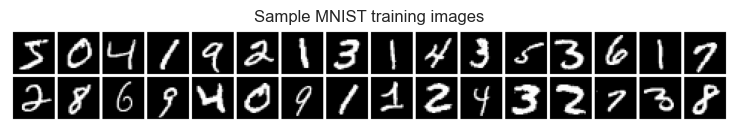

In [6]:
def load_images(name="MNIST"):
    """Download a torchvision dataset and return tensors (N,1,28,28) in [0,1] already on the device."""
    cls = getattr(torchvision.datasets, name)
    tr, te = cls("data", train=True, download=True), cls("data", train=False, download=True)
    to_t = lambda ds: ds.data.float().div(255.).unsqueeze(1).to(device)
    return to_t(tr), tr.targets.clone(), to_t(te), te.targets.clone(), tr.classes

def batches(X, bs, shuffle=True):
    idx = torch.randperm(len(X), device=X.device) if shuffle else torch.arange(len(X), device=X.device)
    for i in range(0, len(X), bs):
        yield X[idx[i:i + bs]]

def train_vae(model, Xtr, Xte, epochs=5, beta=1.0, lr=1e-3, bs=128, verbose=True):
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    hist = {k: [] for k in ["train_total", "train_recon", "train_kl", "test_total", "test_recon", "test_kl"]}
    for ep in range(1, epochs + 1):
        model.train(); t0 = time.time(); s = np.zeros(3)
        for xb in batches(Xtr, bs):
            x_hat, mu, logvar = model(xb)
            loss, rec, kl = vae_loss(x_hat, xb, mu, logvar, beta)
            opt.zero_grad(); loss.backward(); opt.step()
            s += [loss.item(), rec.item(), kl.item()]
        s /= len(Xtr)                                   # per-image averages
        te = evaluate(model, Xte, beta)
        for k, v in zip(hist, list(s) + list(te)): hist[k].append(v)
        if verbose:
            print(f"epoch {ep}/{epochs} | train total={s[0]:.2f} recon={s[1]:.2f} KL={s[2]:.2f} "
                  f"| test total={te[0]:.2f} recon={te[1]:.2f} KL={te[2]:.2f} ({time.time()-t0:.1f}s)")
    return hist

@torch.no_grad()
def evaluate(model, X, beta=1.0, bs=1000):
    model.eval(); s = np.zeros(3)
    for xb in batches(X, bs, shuffle=False):
        x_hat, mu, logvar = model(xb)
        s += [t.item() for t in vae_loss(x_hat, xb, mu, logvar, beta)]
    return s / len(X)

@torch.no_grad()
def encode_mu(model, X, bs=1000):
    model.eval()
    return torch.cat([model.encode(xb)[0] for xb in batches(X, bs, shuffle=False)]).cpu().numpy()

def show_grid(imgs, nrow, title=None, ax=None, size=1.0):
    imgs = imgs.detach().cpu().reshape(-1, 1, 28, 28)
    grid = torchvision.utils.make_grid(imgs, nrow=nrow, padding=2, pad_value=1).permute(1, 2, 0).numpy()
    if ax is None:
        plt.figure(figsize=(nrow * size, (len(imgs) // nrow) * size)); ax = plt.gca()
    ax.imshow(grid, cmap="gray"); ax.axis("off")
    if title: ax.set_title(title)

Xtr, ytr, Xte, yte, classes = load_images("MNIST")
print("Train:", tuple(Xtr.shape), " Test:", tuple(Xte.shape), " pixel range:", Xtr.min().item(), "-", Xtr.max().item())
show_grid(Xtr[:32], nrow=16, title="Sample MNIST training images", size=0.6)

### 6.2 Model, loss and training loop
* **Encoder:** 784 → 400 (ReLU) → two heads: $\mu$ and $\log\sigma^2$
* **Reparameterisation:** $z = \mu + \sigma\odot\epsilon$
* **Decoder:** latent → 400 (ReLU) → 784 (Sigmoid)
* **Loss:** BCE (sum over pixels) + KL, i.e. exactly the negative ELBO derived above

In [7]:
class VAE(nn.Module):
    """Fully-connected VAE:  784 -> 400 -> (mu, logvar) [latent_dim]  ->  400 -> 784"""
    def __init__(self, latent_dim=10, hidden=400):
        super().__init__()
        self.latent_dim = latent_dim
        # ----- Encoder  q_phi(z|x) -----
        self.enc = nn.Sequential(nn.Flatten(), nn.Linear(784, hidden), nn.ReLU())
        self.fc_mu = nn.Linear(hidden, latent_dim)
        self.fc_logvar = nn.Linear(hidden, latent_dim)
        # ----- Decoder  p_theta(x|z) -----
        self.dec = nn.Sequential(nn.Linear(latent_dim, hidden), nn.ReLU(),
                                 nn.Linear(hidden, 784), nn.Sigmoid())

    def encode(self, x):
        h = self.enc(x)
        return self.fc_mu(h), self.fc_logvar(h)

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)          # sigma = exp(log(sigma^2)/2)
        eps = torch.randn_like(std)            # eps ~ N(0, I)
        return mu + std * eps                  # z = mu + sigma * eps

    def decode(self, z):
        return self.dec(z).view(-1, 1, 28, 28)

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        return self.decode(z), mu, logvar

def vae_loss(x_hat, x, mu, logvar, beta=1.0):
    """Returns (total, reconstruction, KL), all SUMMED over the batch.
       recon = BCE(x_hat, x)                      ~  -E_q[log p(x|z)]
       KL    = -1/2 * sum(1 + log s^2 - mu^2 - s^2)  =  KL(q(z|x) || N(0, I))"""
    recon = F.binary_cross_entropy(x_hat.reshape(len(x), -1), x.reshape(len(x), -1), reduction="sum")
    kl = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp())
    return recon + beta * kl, recon, kl

print(VAE(latent_dim=10))

VAE(
  (enc): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=400, bias=True)
    (2): ReLU()
  )
  (fc_mu): Linear(in_features=400, out_features=10, bias=True)
  (fc_logvar): Linear(in_features=400, out_features=10, bias=True)
  (dec): Sequential(
    (0): Linear(in_features=10, out_features=400, bias=True)
    (1): ReLU()
    (2): Linear(in_features=400, out_features=784, bias=True)
    (3): Sigmoid()
  )
)


### 6.3 Effect of the latent-space dimension

We train the **same architecture** with latent dimensions **2, 5, 10 and 20**, for 3 epochs each. All numbers are **per image** (BCE summed over 784 pixels).

In [8]:
LATENT_DIMS = [2, 5, 10, 20]
EPOCHS = 3
models, histories = {}, {}
for d in LATENT_DIMS:
    print(f"\n===== latent_dim = {d} =====")
    set_seed(42)
    m = VAE(latent_dim=d).to(device)
    histories[d] = train_vae(m, Xtr, Xte, epochs=EPOCHS)
    models[d] = m


===== latent_dim = 2 =====


epoch 1/3 | train total=189.79 recon=183.88 KL=5.91 | test total=170.10 recon=164.47 KL=5.63 (2.8s)


epoch 2/3 | train total=167.31 recon=161.95 KL=5.36 | test total=164.04 recon=158.73 KL=5.31 (1.8s)


epoch 3/3 | train total=163.24 recon=157.85 KL=5.40 | test total=161.60 recon=156.13 KL=5.48 (1.8s)

===== latent_dim = 5 =====


epoch 1/3 | train total=167.23 recon=156.87 KL=10.36 | test total=140.66 recon=129.65 KL=11.01 (2.5s)


epoch 2/3 | train total=137.88 recon=127.10 KL=10.77 | test total=134.99 recon=124.24 KL=10.75 (1.9s)


... (3 outputs left out)

epoch 3/3 | train total=119.49 recon=102.23 KL=17.26 | test total=117.02 recon=99.05 KL=17.96 (1.8s)

===== latent_dim = 20 =====


epoch 1/3 | train total=163.33 recon=147.86 KL=15.47 | test total=127.08 recon=106.15 KL=20.92 (2.2s)


epoch 2/3 | train total=121.51 recon=99.43 KL=22.07 | test total=115.53 recon=92.02 KL=23.51 (1.9s)


epoch 3/3 | train total=114.47 recon=90.56 KL=23.92 | test total=111.81 recon=86.96 KL=24.85 (2.1s)


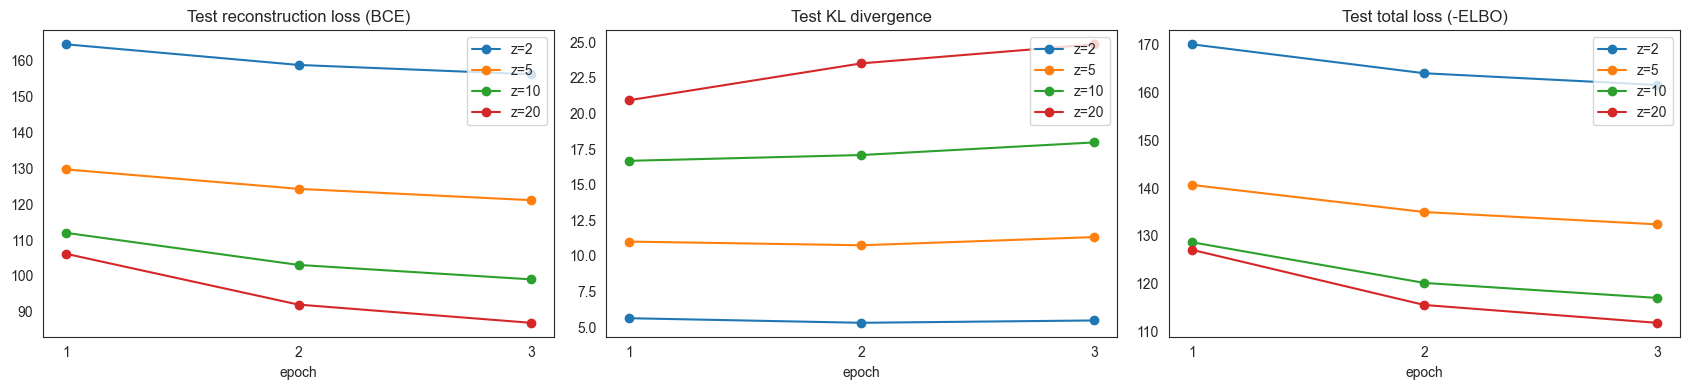

,Recon (BCE),KL,Total (-ELBO),Pixel MSE
latent dim,,,,
2,156.13,5.48,161.60,0.04610
5,121.09,11.32,132.42,0.03150
10,99.05,17.96,117.02,0.02204
20,86.96,24.85,111.81,0.01690


In [9]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
for d in LATENT_DIMS:
    h = histories[d]; ep = range(1, EPOCHS + 1)
    axes[0].plot(ep, h["test_recon"], "o-", label=f"z={d}")
    axes[1].plot(ep, h["test_kl"], "o-", label=f"z={d}")
    axes[2].plot(ep, h["test_total"], "o-", label=f"z={d}")
for ax, t in zip(axes, ["Test reconstruction loss (BCE)", "Test KL divergence", "Test total loss (-ELBO)"]):
    ax.set_title(t); ax.set_xlabel("epoch"); ax.legend(); ax.set_xticks(range(1, EPOCHS + 1))
plt.tight_layout(); plt.show()

summary = pd.DataFrame({d: {"Recon (BCE)": histories[d]["test_recon"][-1], "KL": histories[d]["test_kl"][-1],
                            "Total (-ELBO)": histories[d]["test_total"][-1]} for d in LATENT_DIMS}).T.round(2)
summary["Pixel MSE"] = [round(F.mse_loss(models[d](Xte[:2000])[0], Xte[:2000]).item(), 5) for d in LATENT_DIMS]
summary.index.name = "latent dim"
summary

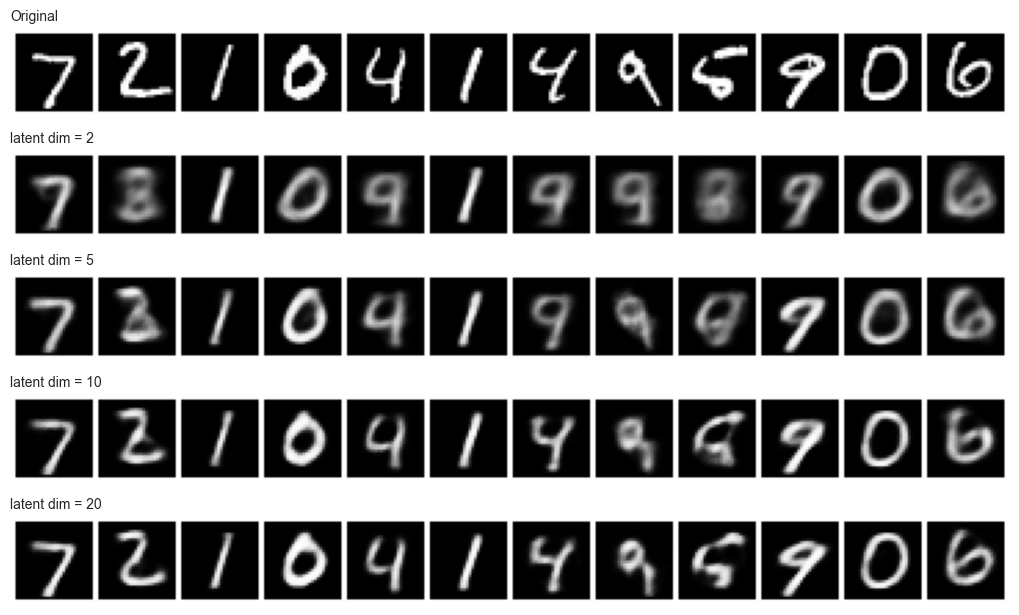

In [10]:
# Visual comparison of reconstructions
set_seed(0)
x = Xte[:12]
rows = [x]
with torch.no_grad():
    for d in LATENT_DIMS:
        models[d].eval(); mu_, _ = models[d].encode(x); rows.append(models[d].decode(mu_))
fig, axes = plt.subplots(len(rows), 1, figsize=(12, 1.25 * len(rows)))
for ax, r, name in zip(axes, rows, ["Original"] + [f"latent dim = {d}" for d in LATENT_DIMS]):
    show_grid(r, nrow=12, ax=ax); ax.set_title(name, fontsize=10, loc="left")
plt.tight_layout(); plt.show()

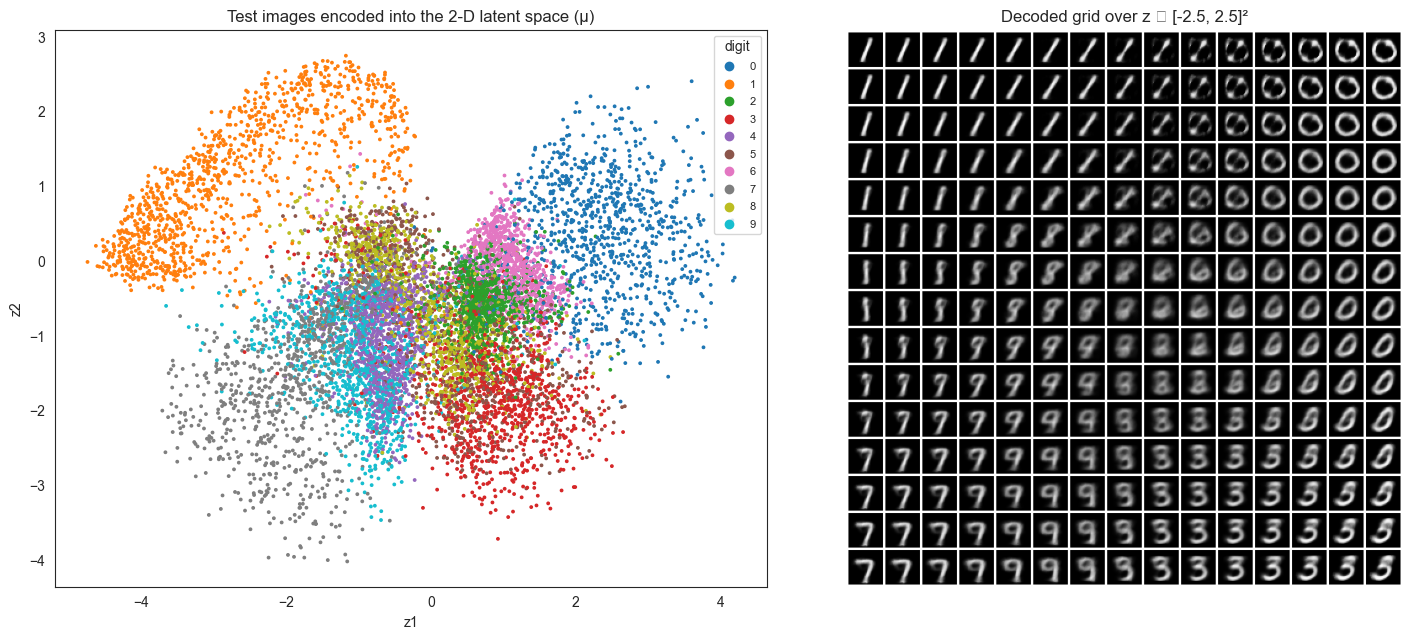

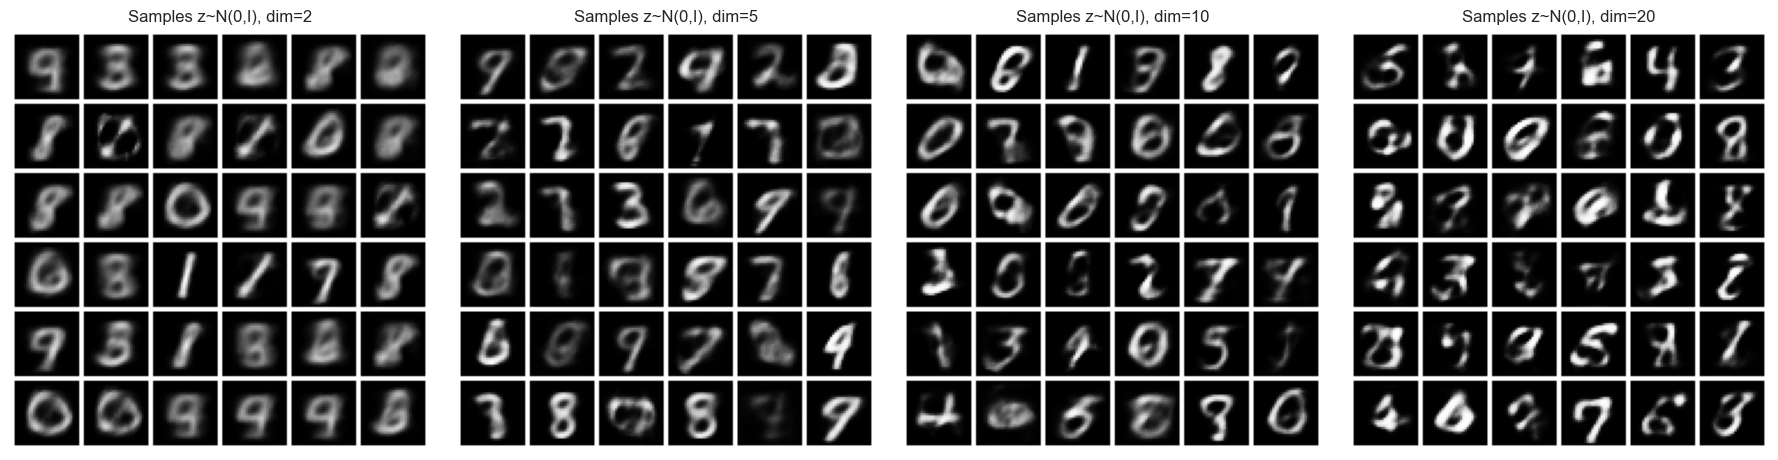

In [11]:
# 2-D latent space: we can visualise it directly
m2 = models[2]
Z = encode_mu(m2, Xte)
fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))
sc = axes[0].scatter(Z[:, 0], Z[:, 1], c=yte.numpy(), cmap="tab10", s=3)
axes[0].legend(*sc.legend_elements(), title="digit", fontsize=8, loc="upper right")
axes[0].set_title("Test images encoded into the 2-D latent space (μ)"); axes[0].set_xlabel("z1"); axes[0].set_ylabel("z2")
# decode a grid of latent points -> the learned "manifold"
n = 15; g = np.linspace(-2.5, 2.5, n)
zz = torch.tensor([[a, b] for b in g[::-1] for a in g], dtype=torch.float32, device=device)
with torch.no_grad(): imgs = m2.decode(zz)
show_grid(imgs, nrow=n, ax=axes[1], title="Decoded grid over z ∈ [-2.5, 2.5]²")
plt.tight_layout(); plt.show()

# Random generation from the prior for each latent size
fig, axes = plt.subplots(1, len(LATENT_DIMS), figsize=(18, 4.5))
for ax, d in zip(axes, LATENT_DIMS):
    with torch.no_grad(): s = models[d].decode(torch.randn(36, d, device=device))
    show_grid(s, nrow=6, ax=ax, title=f"Samples z~N(0,I), dim={d}")
plt.tight_layout(); plt.show()

### 6.4 Analysis: effect of latent dimension on reconstruction quality

* **Reconstruction improves as the latent dimension grows.** Test BCE falls **156.1 → 121.1 → 99.1 → 87.0** and pixel MSE falls **0.046 → 0.032 → 0.022 → 0.017** for 2 → 5 → 10 → 20 dimensions. A 2-D bottleneck can only store the "digit identity + rough style", so reconstructions are blurry and sometimes show the **wrong digit** (e.g. 4 ↔ 9, 3 ↔ 5). With 10–20 dimensions, stroke thickness, slant and details are kept.
* **The KL term grows with the latent dimension** (**5.5 → 11.3 → 18.0 → 24.9**), because the encoder uses more dimensions to store information, and each used dimension costs KL. The total loss (−ELBO) still decreases (**161.6 → 132.4 → 117.0 → 111.8**), so the extra capacity is worth it.
* **Diminishing returns:** the gain in total loss shrinks from 29.2 (2 → 5) to 15.4 (5 → 10) to only 5.2 (10 → 20). Each extra dimension stores less new information. With longer training, a VAE typically switches off dimensions it does not need (they collapse to the prior, $\mu\approx0, \sigma\approx1$), because they would only add KL cost.
* **Trade-off with generation and interpretability:** the 2-D model is the easiest to visualise. Its latent space is smooth and organised by digit class, and the decoded grid morphs continuously between digits. Larger latent spaces reconstruct better, but random prior samples can contain more "in-between" or unrealistic shapes, because more of the prior volume is not covered by the encoded data.

**Conclusion:** a small latent space (2–5) gives a compact, interpretable but lossy representation. A medium one (around 10–20) gives the best balance between reconstruction quality and a well-regularised generative latent space for MNIST.